## Programming for Data Science (PDS) Group Project 2026/2027

###  Group Information:
Abu Nayem - 20251437

Fatima Zahra - 20251224

Rasel Muhammad - 20241622

Umar Mansoor - 20232081


* **GitHub Repository:** https://github.com/raslmm/pds-music-analysis

---


## 1. Environment Setup and Data Importing

In [9]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

### 1.1 Package Versions
To avoid situations where we have conflicting versions, below we verify and document the exact versions of all libraries used throughout this project to guarantee reproducibility.

In [10]:
# List of primary and secondary packages used in the project
packages = [
    ("pandas", pd.__version__),
    ("numpy", np.__version__),
    ("matplotlib", mpl.__version__),
    ("seaborn", sns.__version__),
]

# Displaying a dataframe for the environment packages
df_env = pd.DataFrame(packages, columns=["Package", "Version"])
print("=" * 60)
print("PROGRAMMING FOR DATA SCIENCE 2026/2027 - ENVIRONMENT")
print("=" * 60)
print(df_env.to_string(index=False))

PROGRAMMING FOR DATA SCIENCE 2026/2027 - ENVIRONMENT
   Package Version
    pandas   2.2.2
     numpy  1.26.4
matplotlib   3.9.2
   seaborn  0.13.2


### 1.2 Data Importing & Inspection

Now, we load the dataset `artist_streams.csv` and do an initial inspection to verify the data. And some summary statistics as well for the numerical values.


In [11]:
df_raw = pd.read_csv("../data/artist_streams.csv")
print(f"Total Rows: {df_raw.shape[0]} | Total Columns: {df_raw.shape[1]}")

Total Rows: 511 | Total Columns: 15


## 2. Exploratory Data Analysis
In this part we will inspect the data and analyse what to do with them

In [12]:
# Show the first 5 rows
df_raw.head()

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01 00:00:00,2026.0
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01 00:00:00,2026.0
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01 00:00:00,2026.0
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01 00:00:00,2026.0
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01 00:00:00,2026.0


In [13]:
# Show the last 5 rows
df_raw.tail()

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
506,496,The Marías,NaN,United States,English,Pop,Group,2017.0,7029.1,5774.4,1261.4,5705.9,1323.2,2026-07-01 00:00:00,2026.0
507,497,Limp Bizkit,Male,United States,English,Nu Metal,Group,1997.0,7018.9,7018.4,5.4,6806.0,212.9,2026-07-01 00:00:00,2026.0
508,498,Korn,Male,United States,English,Metal,Group,1994.0,6976.4,4188.4,2798.5,6414.9,561.5,2026-07-01 00:00:00,2026.0
509,499,Omar Courtz,Male,United States,Spanish,Reggaeton,Solo,2017.0,6972.0,6956.0,20.3,1876.2,5095.8,2026-07-01 00:00:00,2026.0
510,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# Schema inspect
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Artist ID              511 non-null    int64  
 1   Artist Name            510 non-null    object 
 2   Sex                    486 non-null    object 
 3   Country of Origin      510 non-null    object 
 4   Primary Language       510 non-null    object 
 5   Primary Genre          510 non-null    object 
 6   Artist Type            510 non-null    object 
 7   Debut Year             510 non-null    float64
 8   Total Streams          505 non-null    float64
 9   Lead Streams           504 non-null    float64
 10  Feature Streams        499 non-null    float64
 11  Solo Streams           506 non-null    float64
 12  Collaborative Streams  509 non-null    float64
 13  Update Date            510 non-null    object 
 14  Year                   510 non-null    float64
dtypes: flo

In [15]:
# Statistical summary of numerical features
df_raw.describe()

,Artist ID,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Year
count,511.000000,510.000000,505.000000,504.000000,499.000000,506.000000,509.000000,510.0
mean,249.956947,2005.201961,16792.430891,12167.685516,4675.364930,8348.897628,8434.201768,2026.0
std,144.020444,13.359191,14771.249974,11833.059565,5954.390999,9600.760173,9551.041044,0.0
min,0.000000,1939.000000,6972.000000,0.000000,0.000000,0.000000,0.000000,2026.0
25%,126.500000,2001.000000,8809.400000,6489.750000,702.800000,2505.925000,1996.600000,2026.0
50%,251.000000,2009.000000,11966.900000,8756.700000,2993.200000,6472.950000,6578.100000,2026.0
75%,373.500000,2014.000000,17738.800000,13456.900000,6096.500000,10127.050000,10929.400000,2026.0
max,500.000000,2023.000000,137492.100000,126177.300000,43710.500000,113421.500000,84168.200000,2026.0


### 2.1 Data quality audit and cleaning

The raw inspection shows duplicated records, one row without an artist name, and missing values in several fields. The cell below standardizes whitespace and data types, removes exact duplicate rows and the row without an artist name, and reports remaining missing values. Missing measurements are left missing rather than imputed. It also checks repeated IDs and the two stream-total breakdowns so inconsistencies are visible.

#### Text normalization and raw checks

In [16]:
# Work on a copy so the original import remains available for comparison.
df_clean = df_raw.copy()

# Trim text and convert whitespace-only cells to missing values.
text_columns = [
    "Artist Name", "Sex", "Country of Origin", "Primary Language",
    "Primary Genre", "Artist Type", "Update Date"
]
def clean_text(value):
    if isinstance(value, str):
        value = value.strip()
        return value if value else pd.NA
    return value

for column in text_columns:
    df_clean[column] = df_clean[column].map(clean_text)

raw_row_count = len(df_clean)
exact_duplicate_rows = int(df_clean.duplicated().sum())
duplicate_id_rows = int(df_clean["Artist ID"].duplicated(keep=False).sum())
conflicting_duplicate_ids = (
    df_clean.groupby("Artist ID", dropna=True)
    .filter(lambda group: len(group.drop_duplicates()) > 1)["Artist ID"]
    .nunique()
)
blank_artist_rows = int(df_clean["Artist Name"].isna().sum())

print(f"Rows imported: {raw_row_count}")
print(f"Exact duplicate rows found: {exact_duplicate_rows}")
print(f"Repeated-ID rows: {duplicate_id_rows}; conflicting duplicate IDs: {conflicting_duplicate_ids}")
print(f"Rows without an artist name: {blank_artist_rows}")


Rows imported: 511
Exact duplicate rows found: 10
Repeated-ID rows: 20; conflicting duplicate IDs: 0
Rows without an artist name: 1


#### Deduplication, types, and missing values

In [17]:
# Remove exact repeated records and the row that has no artist name.
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.loc[df_clean["Artist Name"].notna()].copy()

# Parse numeric fields and dates explicitly; invalid values become missing for review.
numeric_columns = [
    "Artist ID", "Debut Year", "Total Streams", "Lead Streams",
    "Feature Streams", "Solo Streams", "Collaborative Streams", "Year"
]
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")
df_clean["Update Date"] = pd.to_datetime(df_clean["Update Date"], errors="coerce")

remaining_duplicate_ids = int(df_clean["Artist ID"].duplicated().sum())
missing_summary = (
    df_clean.isna().sum().rename("Missing Count").to_frame()
    .query("`Missing Count` > 0").sort_values("Missing Count", ascending=False)
)

print(f"Exact duplicate rows removed: {exact_duplicate_rows}")
print(f"Rows without an artist name removed: {blank_artist_rows}")
print(f"Rows retained for artist-level analysis: {len(df_clean)}")
print(f"Repeated IDs remaining after cleaning: {remaining_duplicate_ids}")
print("Remaining missing values:")
display(missing_summary)


Exact duplicate rows removed: 10
Rows without an artist name removed: 1
Rows retained for artist-level analysis: 500
Repeated IDs remaining after cleaning: 0
Remaining missing values:


,Missing Count
Sex,22
Feature Streams,9
Lead Streams,6
Total Streams,5
Solo Streams,4
Collaborative Streams,1


#### Stream consistency and text encoding checks

In [18]:
# Check the two source-defined stream partitions; do not alter supplied values.
partition_checks = []
for label, components in {
    "Lead + feature": ["Lead Streams", "Feature Streams"],
    "Solo + collaborative": ["Solo Streams", "Collaborative Streams"],
}.items():
    valid = df_clean[["Total Streams", *components]].dropna()
    difference = valid["Total Streams"] - valid[components[0]] - valid[components[1]]
    partition_checks.append({
        "Breakdown": label,
        "Complete records": len(valid),
        "Records differing by more than 0.2 million": int((difference.abs() > 0.2).sum()),
        "Largest absolute difference (millions)": round(float(difference.abs().max()), 1) if len(difference) else pd.NA,
    })
partition_summary = pd.DataFrame(partition_checks)

replacement_character_cells = sum(
    isinstance(value, str) and "\ufffd" in value
    for column in text_columns
    for value in df_clean[column]
)
print(f"Text cells containing a replacement character (manual review needed): {replacement_character_cells}")
print("Stream breakdown consistency (0.2 million tolerance):")
display(partition_summary)


Text cells containing a replacement character (manual review needed): 0
Stream breakdown consistency (0.2 million tolerance):


,Breakdown,Complete records,Records differing by more than 0.2 million,Largest absolute difference (millions)
0,Lead + feature,480,383,89.2
1,Solo + collaborative,490,0,0.0


## 3. Required artist, genre, country, and language counts

Counts below use the cleaned artist-level dataset. Exact duplicate records and the row without an artist name have been removed; artists are counted by unique Artist ID. Missing categories are excluded from category frequencies and remain visible in the quality audit.

In [19]:
unique_artist_count = df_clean["Artist ID"].nunique()
genre_counts = df_clean["Primary Genre"].value_counts(dropna=True)
country_counts = df_clean["Country of Origin"].value_counts(dropna=True)
language_counts = df_clean["Primary Language"].value_counts(dropna=True)
pop_artist_count = sum(
    isinstance(value, str) and value.casefold() == "pop"
    for value in df_clean["Primary Genre"]
)

required_counts = pd.DataFrame([
    {"Question": "Unique artists", "Answer": unique_artist_count},
    {"Question": "Pop artists", "Answer": pop_artist_count},
    {"Question": "Most common primary genre", "Answer": f"{genre_counts.index[0]} ({genre_counts.iloc[0]} artists)"},
    {"Question": "Most common country of origin", "Answer": f"{country_counts.index[0]} ({country_counts.iloc[0]} artists)"},
])
display(required_counts)

print("Top three primary languages:")
display(language_counts.head(3).rename_axis("Primary Language").reset_index(name="Artist Count"))


,Question,Answer
0,Unique artists,500
1,Pop artists,102
2,Most common primary genre,Hip-Hop (115 artists)
3,Most common country of origin,United States (265 artists)


Top three primary languages:


,Primary Language,Artist Count
0,English,340
1,Spanish,105
2,Portuguese,15


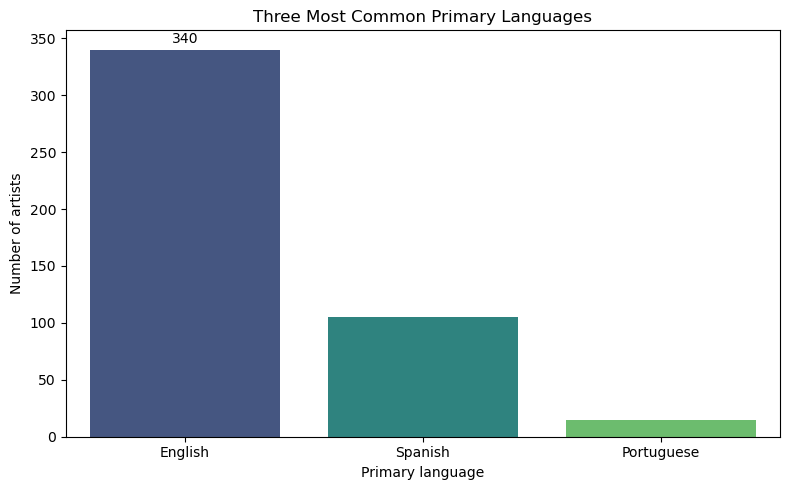

In [20]:
top_language_counts = (
    language_counts.head(3)
    .rename_axis("Primary Language")
    .reset_index(name="Artist Count")
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=top_language_counts,
    x="Primary Language",
    y="Artist Count",
    hue="Primary Language",
    palette="viridis",
    legend=False,
)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Three Most Common Primary Languages")
ax.set_xlabel("Primary language")
ax.set_ylabel("Number of artists")
plt.tight_layout()
plt.show()


## 4. Update dates and stale stream counts

Report the age of the oldest and newest update relative to the date the notebook is run. The project brief defines stream counts last updated before 2026 as out of date; list those artists explicitly.

In [21]:
analysis_date = pd.Timestamp.now().normalize()
valid_update_dates = df_clean["Update Date"].dropna()

update_summary = []
for label, update_date in [
    ("Oldest update", valid_update_dates.min()),
    ("Most recent update", valid_update_dates.max()),
]:
    update_date = update_date.normalize()
    update_summary.append({
        "Update": label,
        "Date": update_date.strftime("%A, %d %B %Y"),
        "Days before analysis date": int((analysis_date - update_date).days),
    })

print(f"Analysis date: {analysis_date.strftime('%A, %d %B %Y')}")
display(pd.DataFrame(update_summary))

outdated_artists = (
    df_clean.loc[df_clean["Update Date"] < pd.Timestamp("2026-01-01"), ["Artist Name", "Update Date"]]
    .sort_values(["Update Date", "Artist Name"])
    .copy()
)
outdated_artists["Update Date"] = outdated_artists["Update Date"].dt.strftime("%d %B %Y")
print(f"Artists whose stream counts were last updated before 2026: {len(outdated_artists)}")
display(outdated_artists.reset_index(drop=True))


Analysis date: Wednesday, 25 November 2026


,Update,Date,Days before analysis date
0,Oldest update,"Tuesday, 01 July 2025",512
1,Most recent update,"Wednesday, 01 July 2026",147


Artists whose stream counts were last updated before 2026: 10


,Artist Name,Update Date
0,Alejandro Fernández,01 July 2025
1,Elvis Presley,01 July 2025
2,Grupo Frontera,01 July 2025
3,Grupo Menos É Mais,01 July 2025
4,Gucci Mane,01 July 2025
5,Kane Brown,01 July 2025
6,Quavo,01 July 2025
7,SEVENTEEN,01 July 2025
8,ScHoolboy Q,01 July 2025
9,Teddy Swims,01 July 2025


## 5. Career length and total streams

Career length is measured as the dataset extraction year minus debut year, in whole calendar years. The plot uses a logarithmic stream axis because values are strongly skewed. Spearman correlation summarizes the monotonic association; it does not establish that a longer career causes more streams.

Artists included: 495
Rows excluded for a debut year after the extraction year: 0
Spearman correlation between career length and total streams: -0.010


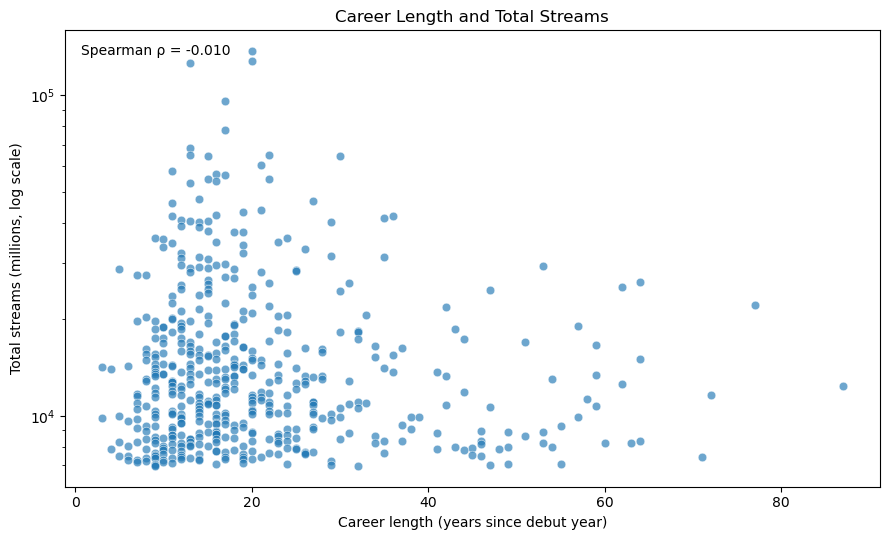

In [22]:
career_data = df_clean.dropna(subset=["Year", "Debut Year", "Total Streams"]).copy()
career_data["Career Length (years)"] = career_data["Year"] - career_data["Debut Year"]
negative_career_rows = int((career_data["Career Length (years)"] < 0).sum())
career_data = career_data.loc[career_data["Career Length (years)"] >= 0].copy()
spearman_rho = career_data[["Career Length (years)", "Total Streams"]].corr(method="spearman").iloc[0, 1]

print(f"Artists included: {len(career_data)}")
print(f"Rows excluded for a debut year after the extraction year: {negative_career_rows}")
print(f"Spearman correlation between career length and total streams: {spearman_rho:.3f}")

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(
    data=career_data,
    x="Career Length (years)",
    y="Total Streams",
    alpha=0.65,
    s=38,
    ax=ax,
)
ax.set_yscale("log")
ax.set_title("Career Length and Total Streams")
ax.set_xlabel("Career length (years since debut year)")
ax.set_ylabel("Total streams (millions, log scale)")
ax.text(
    0.02, 0.97, f"Spearman ρ = {spearman_rho:.3f}",
    transform=ax.transAxes, va="top",
)
plt.tight_layout()
plt.show()


## 6. Collaboration share

For each artist, collaboration share is collaborative streams divided by total streams. Rows with a missing or zero total are excluded from the ranking. The percentage is descriptive and may reflect the limitations of the supplied stream data.

,Artist Name,Collaborative Share (%)
0,Disney,100.0
1,Amitabh Bhattacharya,100.0
2,Irshad Kamil,100.0
3,DJ Luian,100.0
4,Kumaar,100.0


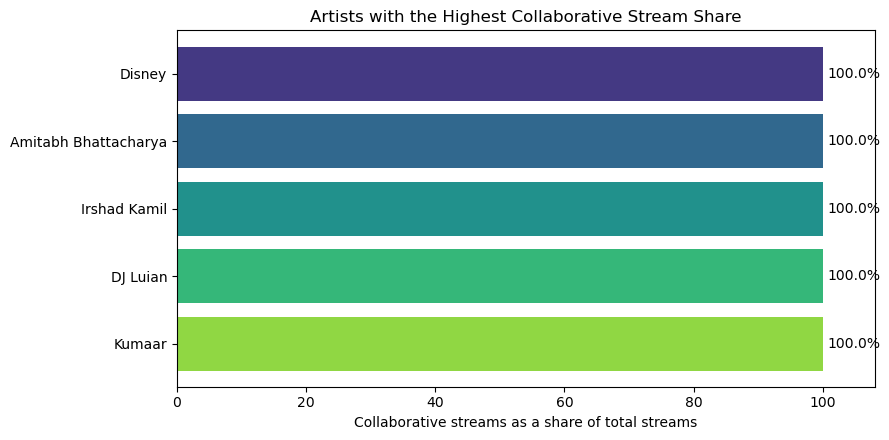

In [23]:
collaboration_data = df_clean[["Artist Name", "Total Streams", "Collaborative Streams"]].dropna().copy()
collaboration_data = collaboration_data.loc[collaboration_data["Total Streams"] > 0].copy()
collaboration_data["Collaborative Share (%)"] = (
    100 * collaboration_data["Collaborative Streams"] / collaboration_data["Total Streams"]
)
top_collaboration_artists = (
    collaboration_data.nlargest(5, "Collaborative Share (%)")
    .sort_values("Collaborative Share (%)", ascending=False)
    .copy()
)
display(top_collaboration_artists[["Artist Name", "Collaborative Share (%)"]].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(
    top_collaboration_artists["Artist Name"],
    top_collaboration_artists["Collaborative Share (%)"],
    color=sns.color_palette("viridis", n_colors=len(top_collaboration_artists)),
)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlim(0, max(105, top_collaboration_artists["Collaborative Share (%)"].max() + 8))
ax.set_title("Artists with the Highest Collaborative Stream Share")
ax.set_xlabel("Collaborative streams as a share of total streams")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


## 7. Three additional comparisons

These comparisons describe the observed top-artist dataset; they do not show that genre, artist type, or language causes streaming success. The genre and language plots focus on the most represented categories so the distributions remain readable, and each summary reports its artist count.

### 7.1 Total streams across common genres

,Artists,Median streams (millions)
Primary Genre,,
EDM,22,14694.90
Hip-Hop,113,13734.10
R&B,31,13065.70
Reggaeton,43,12929.70
Pop,102,12649.15
Regional Mexican,18,11149.60
Rock,59,10616.10
Latin,30,9858.30


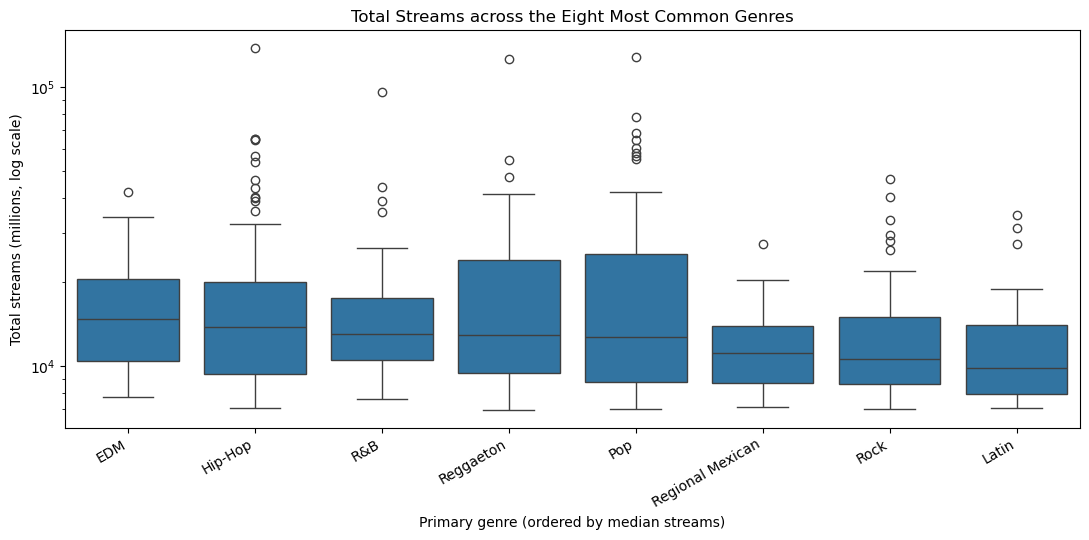

In [24]:
top_genres = df_clean["Primary Genre"].value_counts().head(8).index.tolist()
genre_data = df_clean.loc[
    df_clean["Primary Genre"].isin(top_genres) & df_clean["Total Streams"].notna()
].copy()
genre_summary = (
    genre_data.groupby("Primary Genre")["Total Streams"]
    .agg(Artists="count", Median="median")
    .sort_values("Median", ascending=False)
)
display(genere_summary if False else genre_summary.rename(columns={"Median": "Median streams (millions)"}))

genre_order = genre_summary.index.tolist()
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=genre_data, x="Primary Genre", y="Total Streams", order=genre_order, ax=ax)
ax.set_yscale("log")
ax.set_title("Total Streams across the Eight Most Common Genres")
ax.set_xlabel("Primary genre (ordered by median streams)")
ax.set_ylabel("Total streams (millions, log scale)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### 7.2 Solo artists and groups

,Artists,Median streams (millions)
Artist Type,,
Solo,369,12713.20
Group,126,10589.05


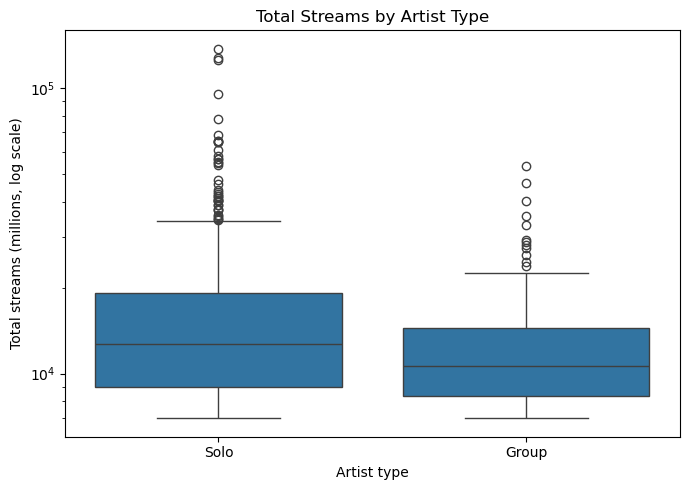

In [25]:
type_data = df_clean.dropna(subset=["Artist Type", "Total Streams"]).copy()
type_summary = (
    type_data.groupby("Artist Type")["Total Streams"]
    .agg(Artists="count", Median="median")
    .sort_values("Median", ascending=False)
)
display(type_summary.rename(columns={"Median": "Median streams (millions)"}))

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=type_data, x="Artist Type", y="Total Streams", order=type_summary.index.tolist(), ax=ax)
ax.set_yscale("log")
ax.set_title("Total Streams by Artist Type")
ax.set_xlabel("Artist type")
ax.set_ylabel("Total streams (millions, log scale)")
plt.tight_layout()
plt.show()


### 7.3 Total streams across common languages

,Artists,Median streams (millions)
Primary Language,,
English,336,12908.0
Spanish,104,11270.1
Hindi,11,10165.0
Portuguese,15,10122.5
German,7,8906.9
Korean,11,8531.3


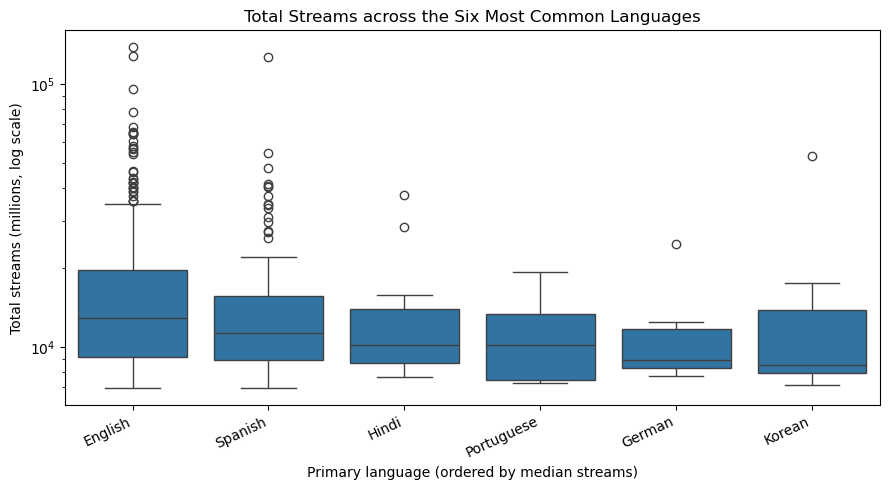

In [26]:
top_languages = df_clean["Primary Language"].value_counts().head(6).index.tolist()
language_data = df_clean.loc[
    df_clean["Primary Language"].isin(top_languages) & df_clean["Total Streams"].notna()
].copy()
language_summary = (
    language_data.groupby("Primary Language")["Total Streams"]
    .agg(Artists="count", Median="median")
    .sort_values("Median", ascending=False)
)
display(language_summary.rename(columns={"Median": "Median streams (millions)"}))

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=language_data,
    x="Primary Language",
    y="Total Streams",
    order=language_summary.index.tolist(),
    ax=ax,
)
ax.set_yscale("log")
ax.set_title("Total Streams across the Six Most Common Languages")
ax.set_xlabel("Primary language (ordered by median streams)")
ax.set_ylabel("Total streams (millions, log scale)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
